In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

In [2]:
print(df)

     Person ID  Gender  Age            Occupation  Sleep Duration  \
0            1    Male   27     Software Engineer             6.1   
1            2    Male   28                Doctor             6.2   
2            3    Male   28                Doctor             6.2   
3            4    Male   28  Sales Representative             5.9   
4            5    Male   28  Sales Representative             5.9   
..         ...     ...  ...                   ...             ...   
369        370  Female   59                 Nurse             8.1   
370        371  Female   59                 Nurse             8.0   
371        372  Female   59                 Nurse             8.1   
372        373  Female   59                 Nurse             8.1   
373        374  Female   59                 Nurse             8.1   

     Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                   6                       42             6   Overweight   
1                

In [3]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Chương 2: Tiền xử lý dữ liệu

In [4]:
import numpy as np
import pandas as pd

# 1. Xử lý giá trị bị khuyết
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# 2. Định dạng dữ liệu
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
df[['Systolic_BP', 'Diastolic_BP']] = (
    df['Blood Pressure'].str.split('/', expand=True).astype(int)
)

# 3. Chuẩn hóa dữ liệu
df['Daily_Steps_MinMax'] = (
    df['Daily Steps'] - df['Daily Steps'].min()
) / (df['Daily Steps'].max() - df['Daily Steps'].min())
df['Age_Zscore'] = (df['Age'] - df['Age'].mean()) / df['Age'].std()

# 4. Chuyển giá trị số thành giá trị phân loại - Binning
bins_sleep = np.linspace(
    df['Sleep Duration'].min(), df['Sleep Duration'].max(), 4
)
sleep_labels = ['Nghỉ ngơi ít', 'Trung bình', 'Nghỉ ngơi nhiều']
df['Sleep_Duration_Bin'] = pd.cut(
    df['Sleep Duration'],
    bins=bins_sleep,
    labels=sleep_labels,
    include_lowest=True,
)

# 5. Chuyển giá trị phân loại thành giá trị số - Encoding
bmi_map = {'Normal': 0, 'Overweight': 1, 'Obese': 2}
df['BMI_Encoded'] = df['BMI Category'].map(bmi_map)

gender_dummies = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
df = pd.concat([df, gender_dummies], axis=1)

print('Hoàn tất tiền xử lý dữ liệu!')

Hoàn tất tiền xử lý dữ liệu!


Chương 3: Trực quan hóa dữ liệu

<Axes: xlabel='Sleep Duration', ylabel='Occupation'>

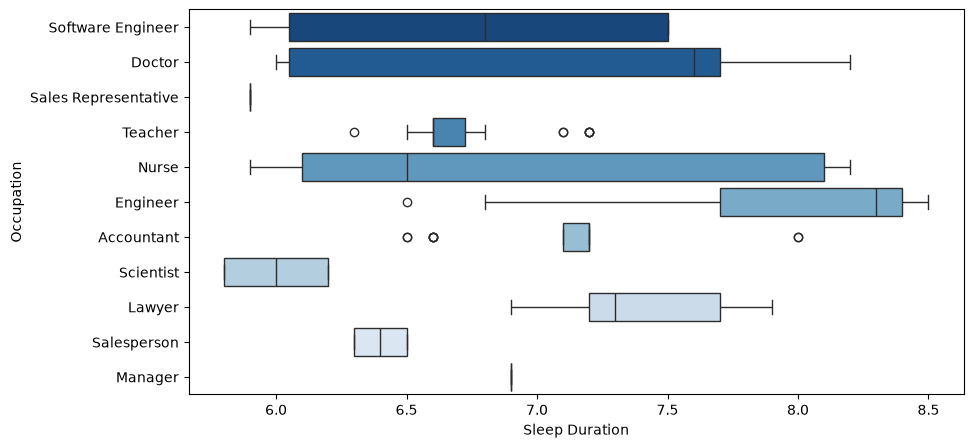

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot: Thời lượng ngủ theo Nghề nghiệp
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='Sleep Duration',
    y='Occupation',
    hue='Occupation',
    palette='Blues_r',
    legend=False
)

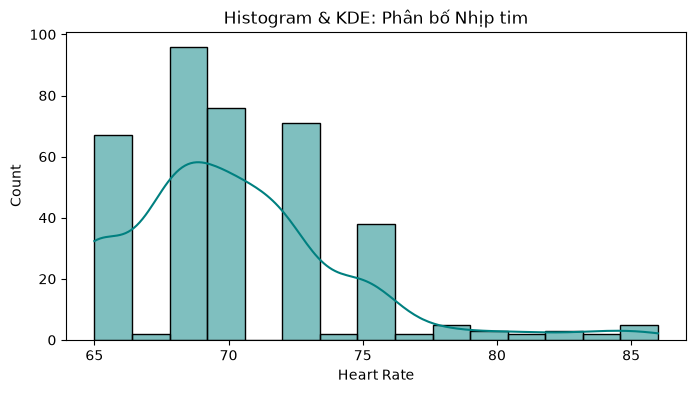

In [6]:
# Histogram & KDE: Phân bố Nhịp tim
plt.figure(figsize=(8, 4))
sns.histplot(df['Heart Rate'], kde=True, bins=15, color='teal')
plt.title('Histogram & KDE: Phân bố Nhịp tim')
plt.show()

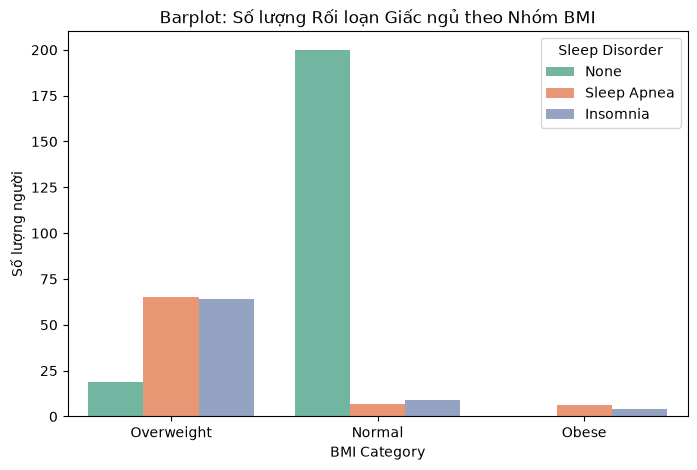

In [7]:
# Barplot: Tỷ lệ Rối loạn giấc ngủ theo nhóm BMI
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='BMI Category', hue='Sleep Disorder', palette='Set2')
plt.title('Barplot: Số lượng Rối loạn Giấc ngủ theo Nhóm BMI')
plt.ylabel('Số lượng người')
plt.show()

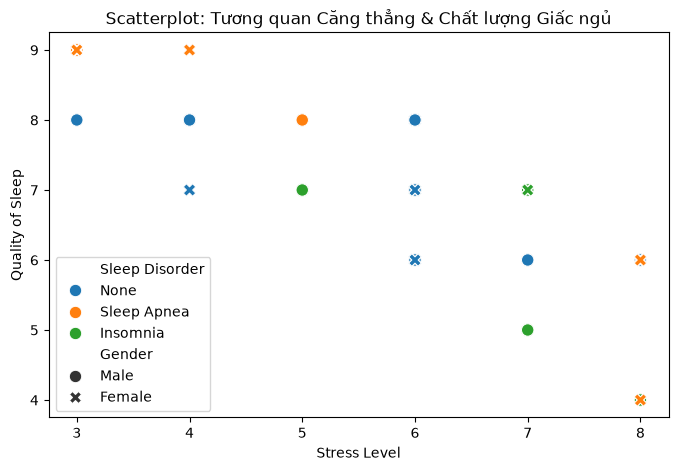

In [8]:
# Scatterplot: Tương quan Căng thẳng & Chất lượng giấc ngủ
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Stress Level',
    y='Quality of Sleep',
    hue='Sleep Disorder',
    style='Gender',
    s=80,
)
plt.title('Scatterplot: Tương quan Căng thẳng & Chất lượng Giấc ngủ')
plt.show()

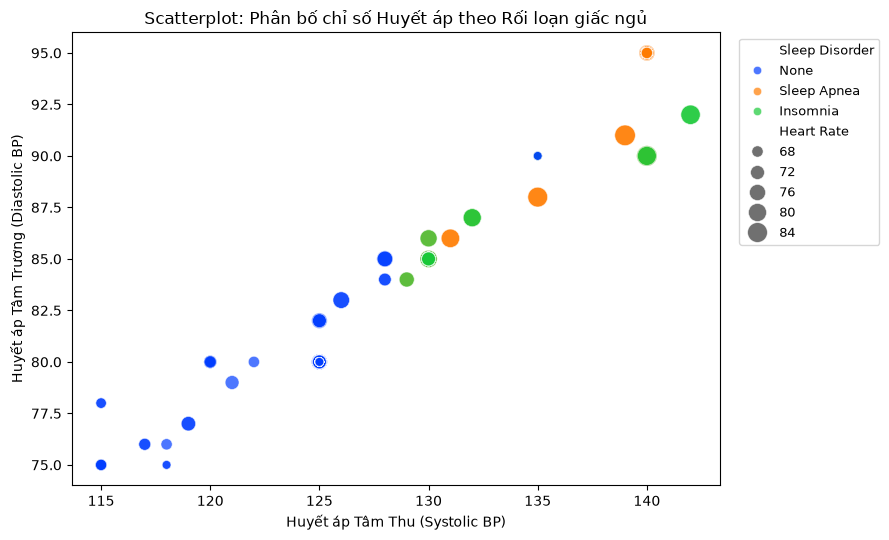

In [9]:
# Scatterplot: Huyết áp Tâm thu & Tâm trương theo Rối loạn giấc ngủ
# (kích thước điểm thể hiện Nhịp tim, giống biểu đồ ở trang "Trực quan hóa dữ liệu" của dashboard)
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=df,
    x='Systolic_BP',
    y='Diastolic_BP',
    hue='Sleep Disorder',
    size='Heart Rate',
    sizes=(40, 220),
    alpha=0.7,
    palette='bright',
)
plt.title('Scatterplot: Phân bố chỉ số Huyết áp theo Rối loạn giấc ngủ')
plt.xlabel('Huyết áp Tâm Thu (Systolic BP)')
plt.ylabel('Huyết áp Tâm Trương (Diastolic BP)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

Chương 4: Công cụ trực quan

<Figure size 800x500 with 0 Axes>

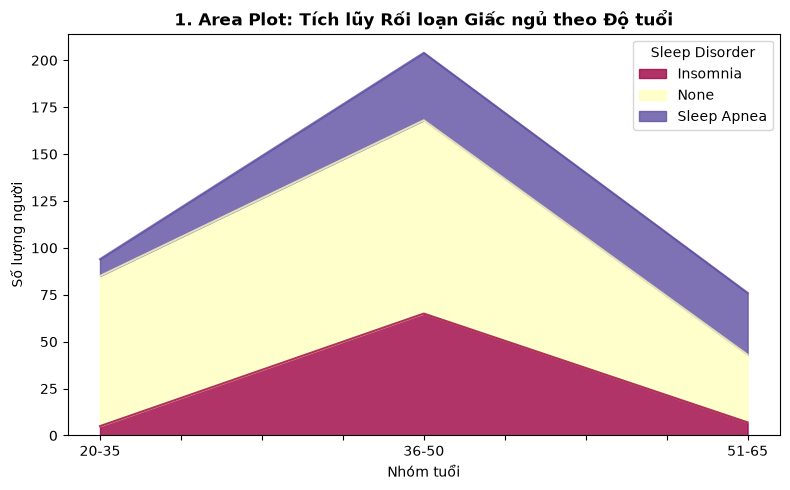

In [10]:
# CHART 1: AREA PLOT
# ==========================================
plt.figure(figsize=(8, 5))
df['Age_Group'] = pd.cut(
    df['Age'], bins=[20, 35, 50, 65], labels = ['20-35', '36-50', '51-65']
)
age_pivot = df.pivot_table(
    index='Age_Group',
    columns='Sleep Disorder',
    values='Person ID',
    aggfunc='count',
).fillna(0)

age_pivot.plot(
    kind='area', stacked=True, colormap='Spectral', alpha=0.8, figsize=(8, 5)
)
plt.title(
    '1. Area Plot: Tích lũy Rối loạn Giấc ngủ theo Độ tuổi',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Nhóm tuổi')
plt.ylabel('Số lượng người')
plt.tight_layout()
plt.show()

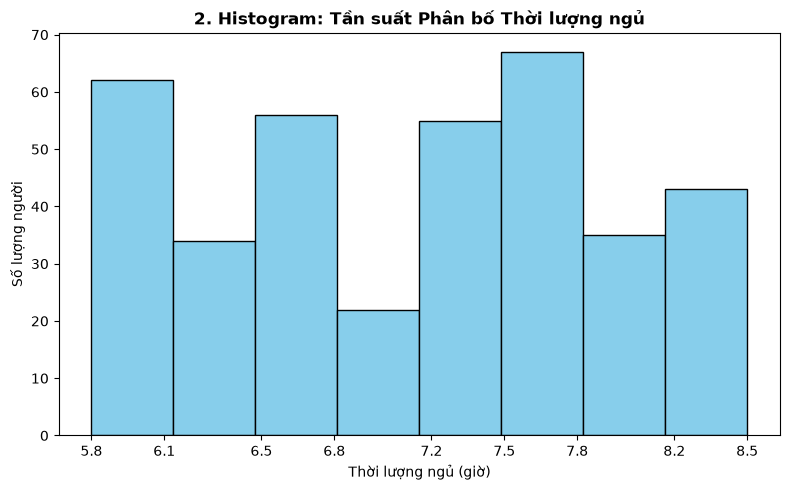

In [11]:
# CHART 2: HISTOGRAM
# ==========================================
plt.figure(figsize=(8, 5))
counts, bin_edges = np.histogram(df['Sleep Duration'], bins=8)

plt.hist(
    df['Sleep Duration'], bins=bin_edges, color='skyblue', edgecolor='black'
)
plt.xticks(np.round(bin_edges, 1))
plt.title(
    '2. Histogram: Tần suất Phân bố Thời lượng ngủ',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Thời lượng ngủ (giờ)')
plt.ylabel('Số lượng người')
plt.tight_layout()
plt.show()

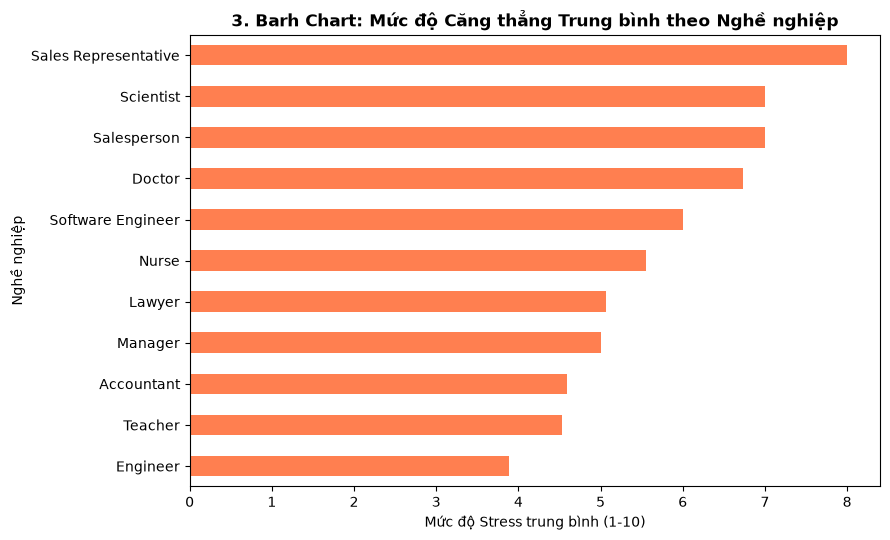

In [12]:
# CHART 3: BARH CHART
# ==========================================
plt.figure(figsize=(9, 5.5))
df.groupby('Occupation')['Stress Level'].mean().sort_values().plot(
    kind='barh', color='coral'
)
plt.title(
    '3. Barh Chart: Mức độ Căng thẳng Trung bình theo Nghề nghiệp',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Mức độ Stress trung bình (1-10)')
plt.ylabel('Nghề nghiệp')
plt.tight_layout()
plt.show()

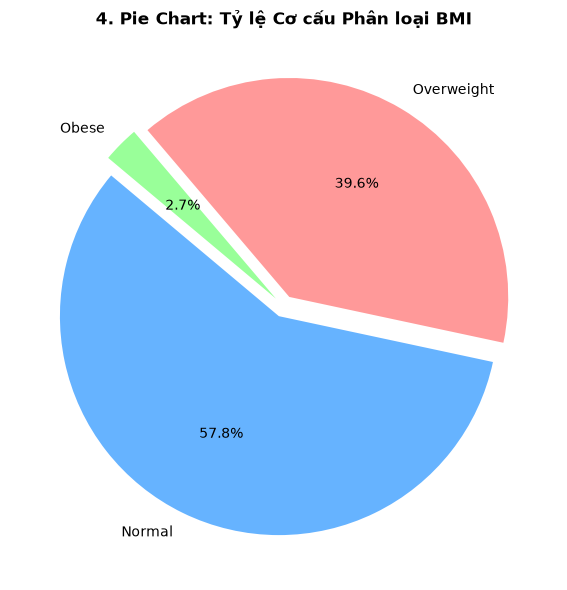

In [13]:
# CHART 4: PIE CHART
# ==========================================
plt.figure(figsize=(7, 6))
bmi_counts = df['BMI Category'].value_counts()

plt.pie(
    bmi_counts,
    labels=bmi_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#66b3ff', '#ff9999', '#99ff99'],
    explode=(0.05, 0.05, 0.05),
)
plt.title(
    '4. Pie Chart: Tỷ lệ Cơ cấu Phân loại BMI', fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

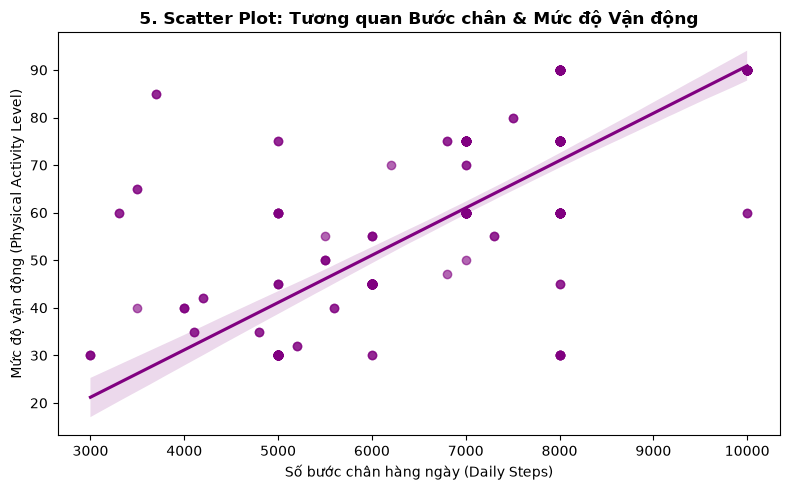

In [14]:
# CHART 5: SCATTER PLOT
# ==========================================
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x='Daily Steps',
    y='Physical Activity Level',
    color='purple',
    scatter_kws={'alpha': 0.6},
)
plt.title(
    '5. Scatter Plot: Tương quan Bước chân & Mức độ Vận động',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Số bước chân hàng ngày (Daily Steps)')
plt.ylabel('Mức độ vận động (Physical Activity Level)')
plt.tight_layout()
plt.show()

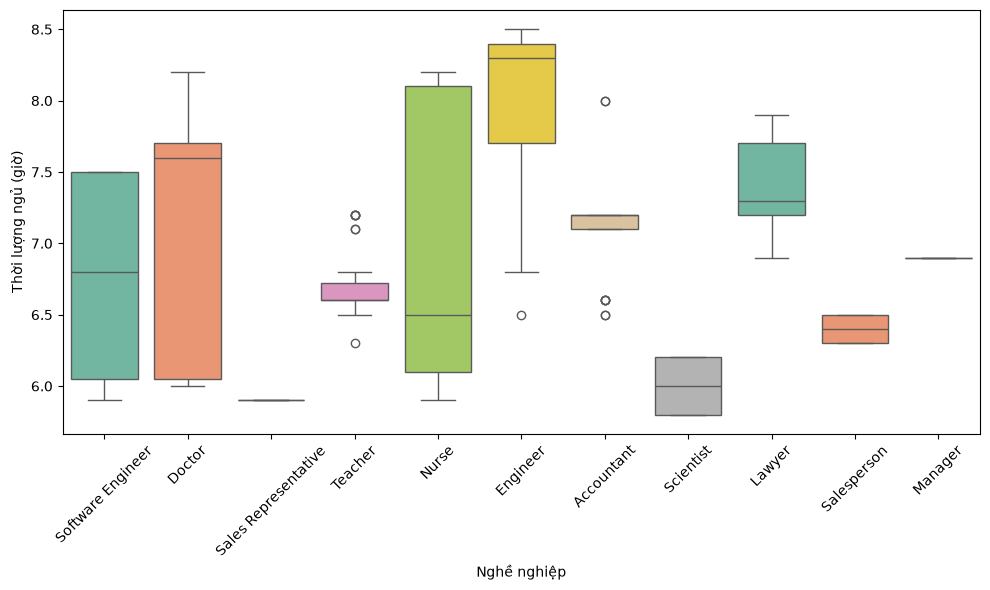

In [15]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='Occupation',            # Biến phân loại trên trục X
    y='Sleep Duration',
    hue='Occupation',          # Gán hue trùng với trục X
    palette='Set2',
    legend=False               # Tắt khung chú thích dư thừa
)
plt.xlabel('Nghề nghiệp')
plt.ylabel('Thời lượng ngủ (giờ)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

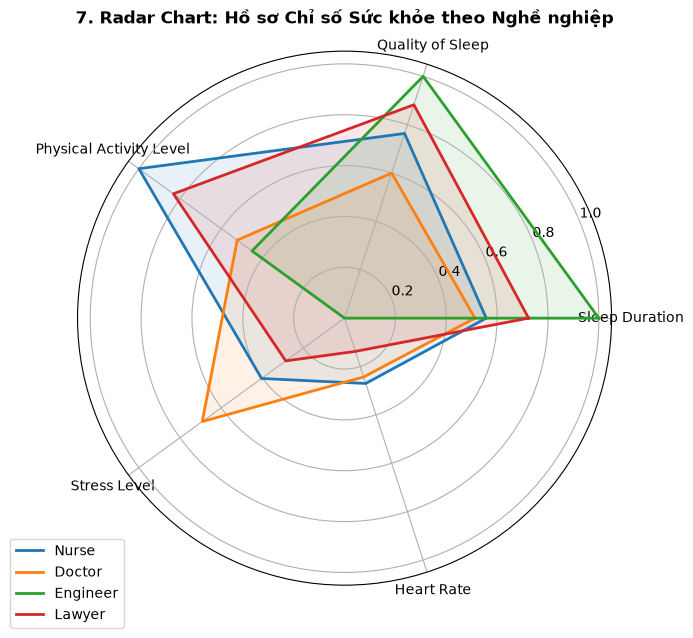

In [16]:
# CHART 7: RADAR CHART
# ==========================================
# So sánh hồ sơ chỉ số sức khỏe của 4 nghề đông người nhất
# (giống biểu đồ ở trang "Công cụ trực quan" của dashboard)
categories = [
    'Sleep Duration',
    'Quality of Sleep',
    'Physical Activity Level',
    'Stress Level',
    'Heart Rate',
]
top_occupations = df['Occupation'].value_counts().head(4).index

# Chuẩn hóa Min-Max trung bình từng chỉ số theo nghề về thang 0-1
df_radar = df.groupby('Occupation')[categories].mean()
df_radar_norm = (df_radar - df_radar.min()) / (df_radar.max() - df_radar.min())

N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for occ in top_occupations:
  values = df_radar_norm.loc[occ].values.flatten().tolist()
  values += values[:1]
  ax.plot(angles, values, linewidth=2, linestyle='solid', label=occ)
  ax.fill(angles, values, alpha=0.1)

plt.xticks(angles[:-1], categories)
ax.set_title(
    '7. Radar Chart: Hồ sơ Chỉ số Sức khỏe theo Nghề nghiệp',
    fontsize=12,
    fontweight='bold',
    pad=20,
)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.tight_layout()
plt.show()

Chương 5: Phân tích thăm dò

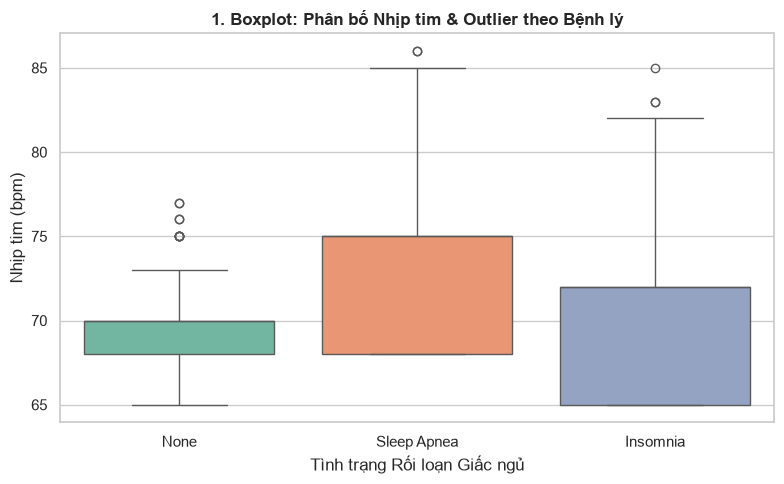

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

sns.set_theme(style='whitegrid')

# Đọc và làm sạch dữ liệu
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
df[['Systolic_BP', 'Diastolic_BP']] = (
    df['Blood Pressure'].str.split('/', expand=True).astype(int)
)

numeric_cols = [
    'Age',
    'Sleep Duration',
    'Quality of Sleep',
    'Physical Activity Level',
    'Stress Level',
    'Heart Rate',
    'Daily Steps',
    'Systolic_BP',
    'Diastolic_BP',
]

# 1. Boxplot - Outlier Nhịp tim
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Sleep Disorder',
    y='Heart Rate',
    hue='Sleep Disorder',  # Thêm hue trùng với x
    palette='Set2',
    legend=False,  # Tắt chú thích dư thừa
)
plt.title(
    '1. Boxplot: Phân bố Nhịp tim & Outlier theo Bệnh lý',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tình trạng Rối loạn Giấc ngủ')
plt.ylabel('Nhịp tim (bpm)')
plt.tight_layout()
plt.show()

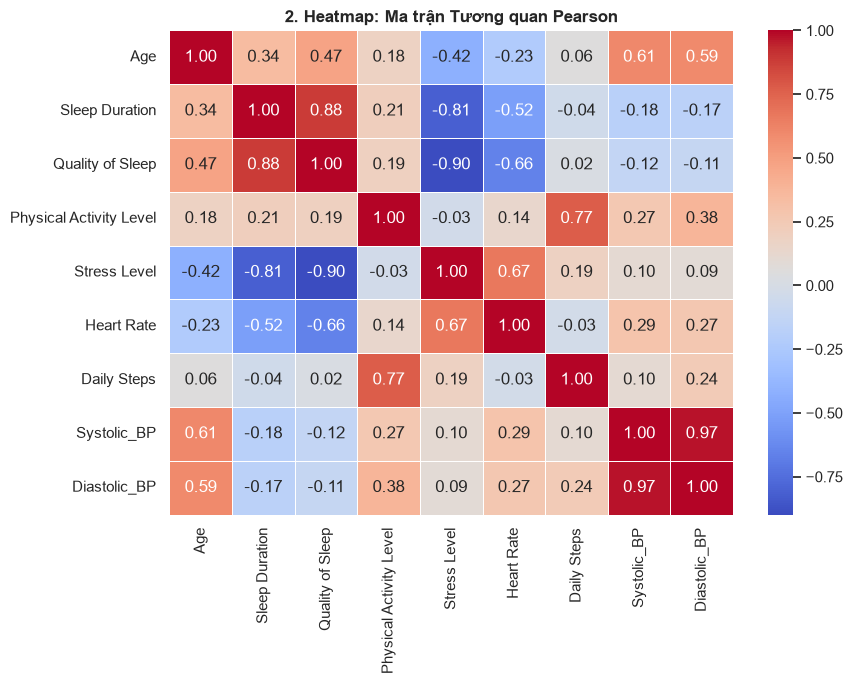

In [18]:
# 2. Heatmap - Ma trận tương quan Pearson
plt.figure(figsize=(9, 7))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
)
plt.title(
    '2. Heatmap: Ma trận Tương quan Pearson', fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

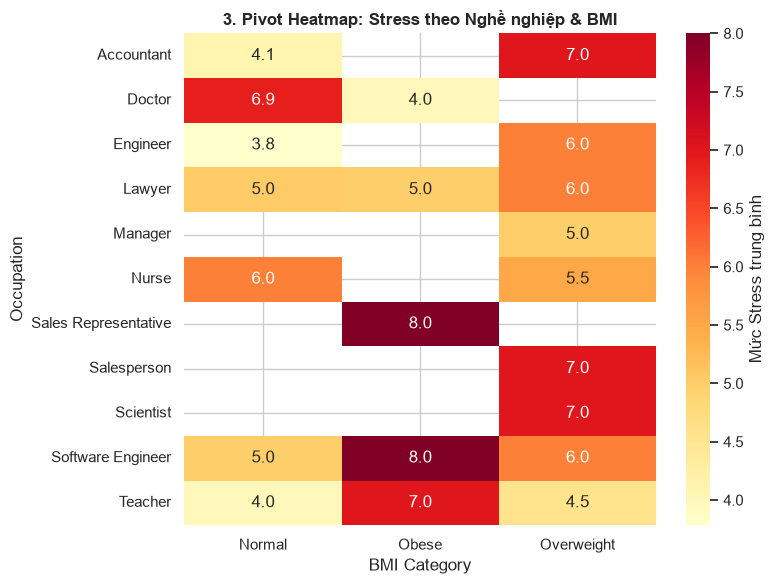

In [19]:
# 3. Pivot Heatmap - Stress theo Nghề nghiệp & BMI
plt.figure(figsize=(8, 6))
pivot_stress = df.pivot_table(
    index='Occupation',
    columns='BMI Category',
    values='Stress Level',
    aggfunc='mean',
)
sns.heatmap(
    pivot_stress,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Mức Stress trung bình'},
)
plt.title(
    '3. Pivot Heatmap: Stress theo Nghề nghiệp & BMI',
    fontsize=12,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

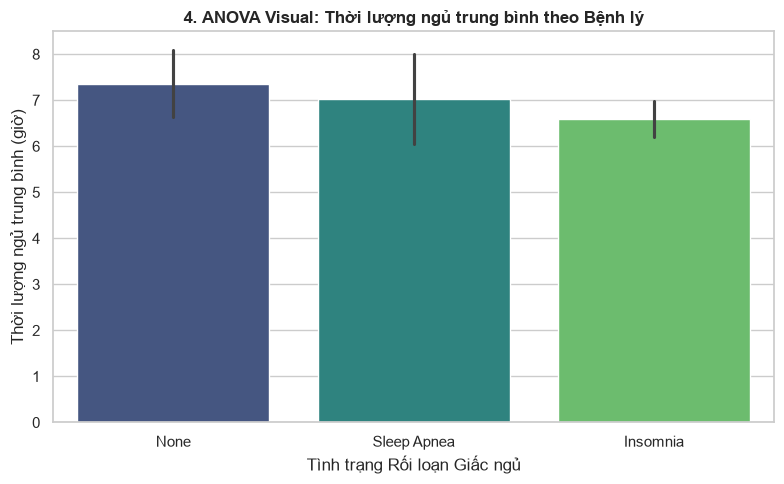

ANOVA: F = 31.91, p-value = 1.63e-13


In [20]:
# 4. ANOVA Visual - Thời lượng ngủ theo Bệnh lý
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x='Sleep Disorder',
    y='Sleep Duration',
    hue='Sleep Disorder',  # Thêm hue bằng với biến ở trục x
    errorbar='sd',
    palette='viridis',
    legend=False,  # Đặt legend=False để tránh hiện bảng chú thích bị lặp
)
plt.title(
    '4. ANOVA Visual: Thời lượng ngủ trung bình theo Bệnh lý',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tình trạng Rối loạn Giấc ngủ')
plt.ylabel('Thời lượng ngủ trung bình (giờ)')
plt.tight_layout()
plt.show()

# Kiểm định ANOVA một yếu tố: thời lượng ngủ có khác nhau giữa các nhóm bệnh lý không?
anova_groups = [g['Sleep Duration'] for _, g in df.groupby('Sleep Disorder')]
f_stat, p_value = stats.f_oneway(*anova_groups)
print(f'ANOVA: F = {f_stat:.2f}, p-value = {p_value:.2e}')

Chương 6: Mô hình hồi quy

SLR Equation: Quality of Sleep = -2.1634 + 1.3287 * Sleep Duration
R2 score: 0.7801
MSE: 0.3143


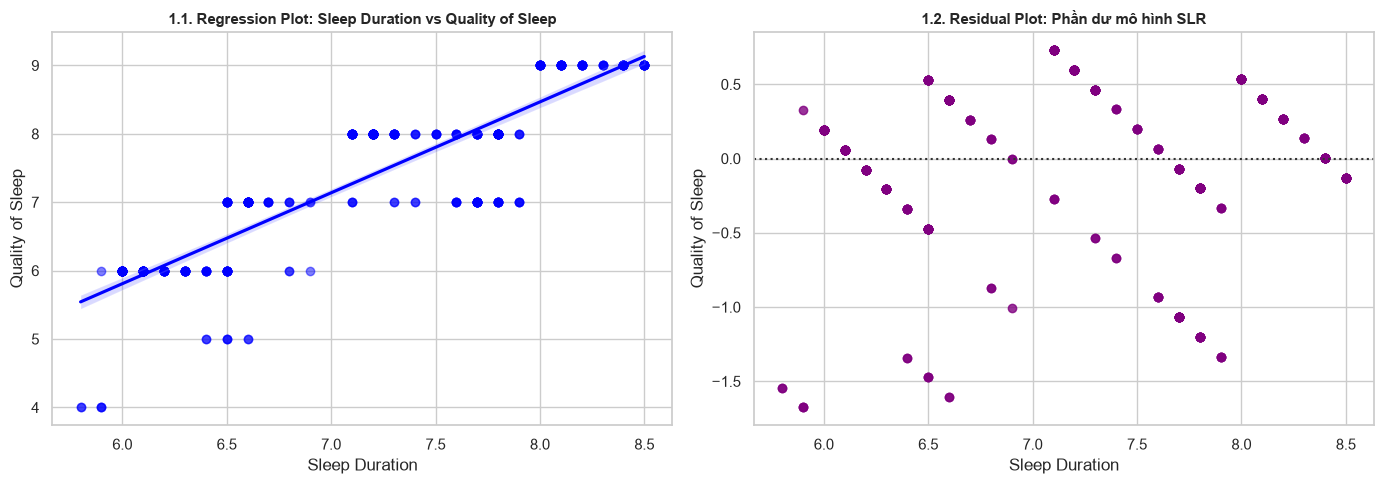

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns

# Tính toán
X_slr = df[['Sleep Duration']]
Y = df['Quality of Sleep']

lm_slr = LinearRegression().fit(X_slr, Y)
y_pred_slr = lm_slr.predict(X_slr)

print(
    f'SLR Equation: Quality of Sleep = {lm_slr.intercept_:.4f} +'
    f' {lm_slr.coef_[0]:.4f} * Sleep Duration'
)
print(f'R2 score: {lm_slr.score(X_slr, Y):.4f}')
print(f'MSE: {mean_squared_error(Y, y_pred_slr):.4f}')

# Vẽ chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(
    ax=axes[0],
    data=df,
    x='Sleep Duration',
    y='Quality of Sleep',
    color='blue',
    scatter_kws={'alpha': 0.5},
)
axes[0].set_title(
    '1.1. Regression Plot: Sleep Duration vs Quality of Sleep',
    fontsize=11,
    fontweight='bold',
)

sns.residplot(
    ax=axes[1],
    data=df,
    x='Sleep Duration',
    y='Quality of Sleep',
    color='purple',
)
axes[1].set_title(
    '1.2. Residual Plot: Phần dư mô hình SLR', fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.show()

MLR Intercept: 7.4881
MLR Coefs: [ 0.60498775 -0.31258837 -0.0454884   0.00650477]
R2 score: 0.8972
MSE: 0.1468


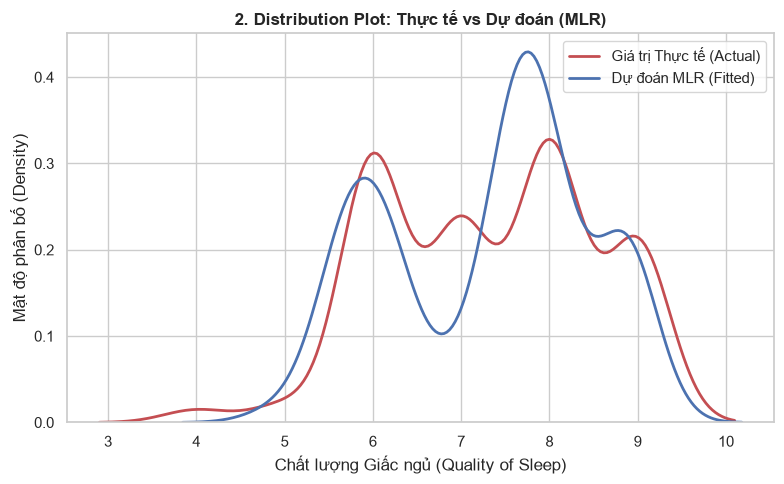

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns

# Tính toán
Z = df[
    ['Sleep Duration', 'Stress Level', 'Heart Rate', 'Physical Activity Level']
]
Y = df['Quality of Sleep']

lm_mlr = LinearRegression().fit(Z, Y)
y_pred_mlr = lm_mlr.predict(Z)

print(f'MLR Intercept: {lm_mlr.intercept_:.4f}')
print(f'MLR Coefs: {lm_mlr.coef_}')
print(f'R2 score: {lm_mlr.score(Z, Y):.4f}')
print(f'MSE: {mean_squared_error(Y, y_pred_mlr):.4f}')

# Vẽ chart
plt.figure(figsize=(8, 5))
sns.kdeplot(data=Y, color='r', label='Giá trị Thực tế (Actual)', linewidth=2)
sns.kdeplot(
    data=y_pred_mlr, color='b', label='Dự đoán MLR (Fitted)', linewidth=2
)
plt.title(
    '2. Distribution Plot: Thực tế vs Dự đoán (MLR)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Chất lượng Giấc ngủ (Quality of Sleep)')
plt.ylabel('Mật độ phân bố (Density)')
plt.legend()
plt.tight_layout()
plt.show()

Poly Eq: Quality of Sleep = 11.0838 + (-0.8109*Stress) + (0.0185*Stress^2)
R2 score: 0.8093
MSE: 0.2725


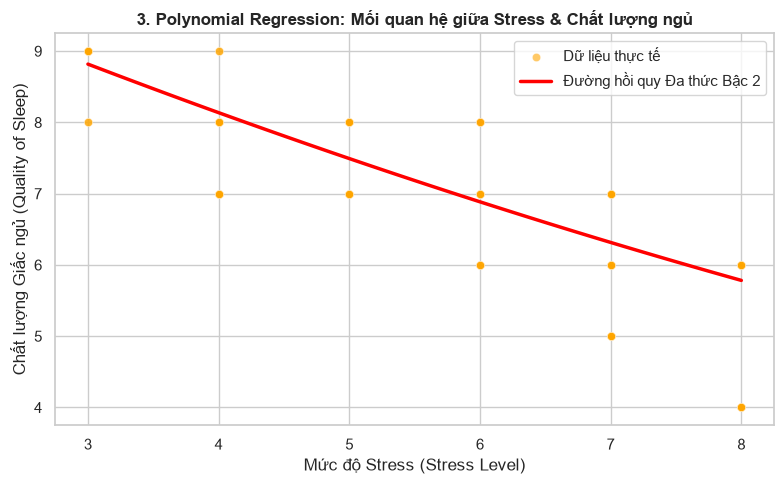

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
import seaborn as sns

df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# 1. Tính toán
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[['Stress Level']])
Y = df['Quality of Sleep']

lm_poly = LinearRegression().fit(X_poly, Y)
y_pred_poly = lm_poly.predict(X_poly)

print(
    'Poly Eq: Quality of Sleep ='
    f' {lm_poly.intercept_:.4f} + ({lm_poly.coef_[0]:.4f}*Stress) +'
    f' ({lm_poly.coef_[1]:.4f}*Stress^2)'
)
print(f'R2 score: {lm_poly.score(X_poly, Y):.4f}')
print(f'MSE: {mean_squared_error(Y, y_pred_poly):.4f}')

# 2. Tạo DataFrame có tên cột chính xác để tránh cảnh báo (Fix UserWarning)
stress_range = pd.DataFrame(
    {'Stress Level': np.linspace(df['Stress Level'].min(), df['Stress Level'].max(), 100)}
)
stress_range_poly = poly.transform(stress_range)
y_range_pred = lm_poly.predict(stress_range_poly)

# 3. Vẽ biểu đồ
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Stress Level',
    y='Quality of Sleep',
    color='orange',
    alpha=0.6,
    label='Dữ liệu thực tế',
)
plt.plot(
    stress_range['Stress Level'],
    y_range_pred,
    color='red',
    linewidth=2.5,
    label='Đường hồi quy Đa thức Bậc 2',
)
plt.title(
    '3. Polynomial Regression: Mối quan hệ giữa Stress & Chất lượng ngủ',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Mức độ Stress (Stress Level)')
plt.ylabel('Chất lượng Giấc ngủ (Quality of Sleep)')
plt.legend()
plt.tight_layout()
plt.show()

Pipeline R2 score: 0.9591
Pipeline MSE: 0.0585


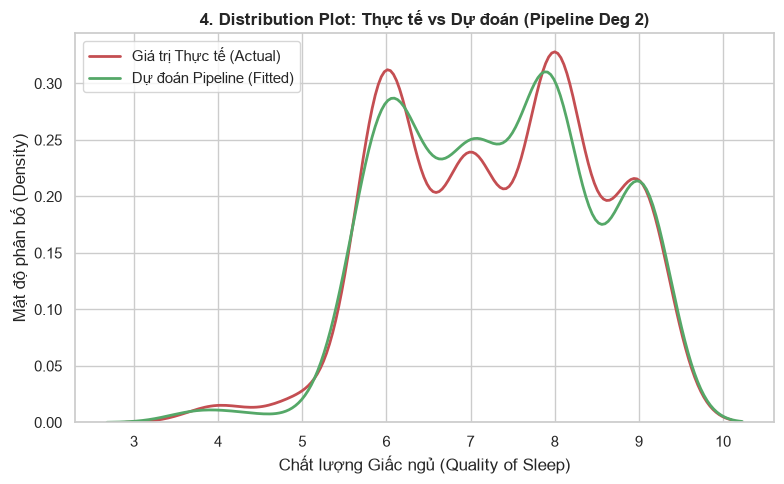

In [24]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import seaborn as sns

df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

Z = df[
    ['Sleep Duration', 'Stress Level', 'Heart Rate', 'Physical Activity Level']
]
Y = df['Quality of Sleep']

# Khởi tạo Pipeline
pipeline_input = [
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression()),
]
pipe = Pipeline(pipeline_input)
pipe.fit(Z, Y)
y_pred_pipe = pipe.predict(Z)

print(f'Pipeline R2 score: {pipe.score(Z, Y):.4f}')
print(f'Pipeline MSE: {mean_squared_error(Y, y_pred_pipe):.4f}')

# Vẽ chart
plt.figure(figsize=(8, 5))
sns.kdeplot(data=Y, color='r', label='Giá trị Thực tế (Actual)', linewidth=2)
sns.kdeplot(
    data=y_pred_pipe,
    color='g',
    label='Dự đoán Pipeline (Fitted)',
    linewidth=2,
)
plt.title(
    '4. Distribution Plot: Thực tế vs Dự đoán (Pipeline Deg 2)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Chất lượng Giấc ngủ (Quality of Sleep)')
plt.ylabel('Mật độ phân bố (Density)')
plt.legend()
plt.tight_layout()
plt.show()

Chương 7: Đánh giá mô hình

Số dòng: 374, số hồ sơ khác nhau: 132
Train R2: 0.8893
Test R2: 0.9143


5-Fold Cross-Validation R2: [0.8833 0.8263 0.9249 0.8965 0.8441]
5-Fold Cross-Validation R2 Mean: 0.8750


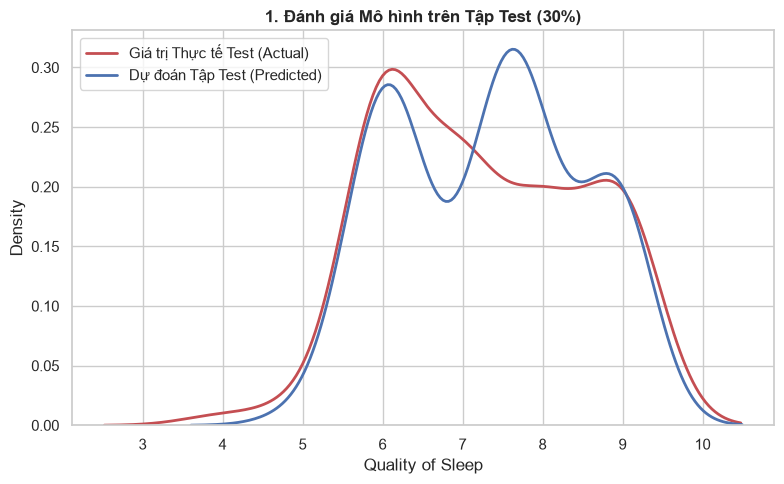

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    cross_val_score,
)
import seaborn as sns

# Làm sạch lại (df vừa được đọc lại từ file ở Chương 6)
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

Y = df['Quality of Sleep']
X_data = df[
    ['Sleep Duration', 'Stress Level', 'Heart Rate', 'Physical Activity Level']
]

# Dữ liệu có nhiều dòng giống hệt nhau (chỉ khác Person ID). Các dòng trùng
# phải nằm cùng một phía Train hoặc Test, nếu không tập Test chỉ là bản sao
# của tập Train và R2 bị thổi phồng.
profile_cols = [c for c in df.columns if c != 'Person ID']
groups = df[profile_cols].astype(str).agg('|'.join, axis=1)
print(f'Số dòng: {len(df)}, số hồ sơ khác nhau: {groups.nunique()}')

# 1. Tách Train / Test (70% - 30%) theo hồ sơ
splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(splitter.split(X_data, Y, groups))
x_train, x_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
y_train, y_test = Y.iloc[train_idx], Y.iloc[test_idx]
g_train = groups.iloc[train_idx]

lr = LinearRegression()
lr.fit(x_train, y_train)

print(f'Train R2: {lr.score(x_train, y_train):.4f}')
print(f'Test R2: {lr.score(x_test, y_test):.4f}')

# 2. Cross Validation (5-Fold) theo hồ sơ
cv_scores = cross_val_score(
    lr, X_data, Y, cv=GroupKFold(n_splits=5), groups=groups
)
print(f'5-Fold Cross-Validation R2: {cv_scores.round(4)}')
print(f'5-Fold Cross-Validation R2 Mean: {cv_scores.mean():.4f}')

# 3. Vẽ biểu đồ Distribution Plot tập Test
plt.figure(figsize=(8, 5))
sns.kdeplot(y_test, color='r', label='Giá trị Thực tế Test (Actual)', linewidth=2)
sns.kdeplot(
    lr.predict(x_test),
    color='b',
    label='Dự đoán Tập Test (Predicted)',
    linewidth=2,
)
plt.title(
    '1. Đánh giá Mô hình trên Tập Test (30%)', fontsize=12, fontweight='bold'
)
plt.xlabel('Quality of Sleep')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

Bậc 1: Train R2 = 0.8075, Test R2 = 0.8042
Bậc 2: Train R2 = 0.8077, Test R2 = 0.8072
Bậc 3: Train R2 = 0.8087, Test R2 = 0.8060
Bậc 4: Train R2 = 0.8607, Test R2 = 0.8774
Bậc 5: Train R2 = 0.8680, Test R2 = 0.8784


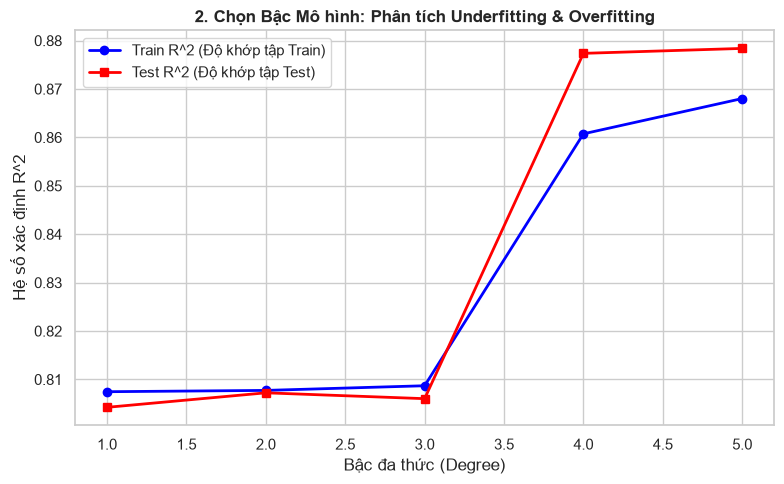

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Dùng lại x_train, x_test, y_train, y_test đã chia theo hồ sơ ở ô trên

# Chuẩn hóa Stress Level trước khi nâng bậc
stress_scaler = StandardScaler().fit(x_train[['Stress Level']])
s_train = stress_scaler.transform(x_train[['Stress Level']])
s_test = stress_scaler.transform(x_test[['Stress Level']])

degrees = [1, 2, 3, 4, 5]
r2_train, r2_test = [], []

for d in degrees:
  poly = PolynomialFeatures(degree=d)
  x_tr_p = poly.fit_transform(s_train)
  x_te_p = poly.transform(s_test)

  m = LinearRegression().fit(x_tr_p, y_train)
  r2_train.append(m.score(x_tr_p, y_train))
  r2_test.append(m.score(x_te_p, y_test))
  print(f'Bậc {d}: Train R2 = {r2_train[-1]:.4f}, Test R2 = {r2_test[-1]:.4f}')

# Vẽ biểu đồ đường Train R2 vs Test R2
plt.figure(figsize=(8, 5))
plt.plot(
    degrees,
    r2_train,
    marker='o',
    color='blue',
    linewidth=2,
    label='Train R^2 (Độ khớp tập Train)',
)
plt.plot(
    degrees,
    r2_test,
    marker='s',
    color='red',
    linewidth=2,
    label='Test R^2 (Độ khớp tập Test)',
)
plt.xlabel('Bậc đa thức (Degree)')
plt.ylabel('Hệ số xác định R^2')
plt.title(
    '2. Chọn Bậc Mô hình: Phân tích Underfitting & Overfitting',
    fontsize=12,
    fontweight='bold',
)
plt.legend()
plt.tight_layout()
plt.show()

Alpha tối ưu: 8.6851 với Validation R2 đạt: 0.9103
Train R2: 0.9583
Test R2: 0.9530


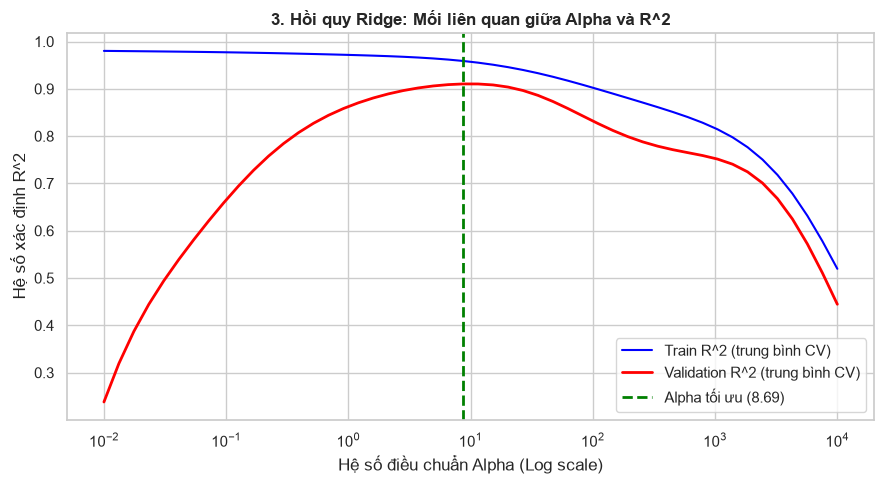

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Dùng lại x_train, x_test, y_train, y_test, g_train đã chia theo hồ sơ

# 1. Pipeline: Chuẩn hóa dữ liệu -> Đa thức bậc 3 -> Ridge
ridge_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(degree=3, include_bias=False)),
    ('model', Ridge()),
])

# 2. Quét dãy alpha (Log scale) bằng 5-Fold CV, chỉ trên tập Train
alphas = np.logspace(-2, 4, 50)
cv_train_scores, cv_val_scores = validation_curve(
    ridge_pipe,
    x_train,
    y_train,
    param_name='model__alpha',
    param_range=alphas,
    cv=GroupKFold(n_splits=5),
    groups=g_train,
)
r_train_scores = cv_train_scores.mean(axis=1)
r_val_scores = cv_val_scores.mean(axis=1)

# Tìm Alpha tối ưu theo điểm Validation
best_idx = np.argmax(r_val_scores)
best_alpha = alphas[best_idx]

# 3. Huấn luyện lại với Alpha tối ưu, chấm một lần trên tập Test
ridge_pipe.set_params(model__alpha=best_alpha).fit(x_train, y_train)
print(
    f'Alpha tối ưu: {best_alpha:.4f} với Validation R2 đạt: {r_val_scores[best_idx]:.4f}'
)
print(f'Train R2: {ridge_pipe.score(x_train, y_train):.4f}')
print(f'Test R2: {ridge_pipe.score(x_test, y_test):.4f}')

# 4. Vẽ biểu đồ Mối liên quan Alpha và R^2
plt.figure(figsize=(9, 5))
plt.plot(alphas, r_train_scores, color='blue', label='Train R^2 (trung bình CV)')
plt.plot(
    alphas,
    r_val_scores,
    color='red',
    linewidth=2,
    label='Validation R^2 (trung bình CV)',
)
plt.xscale('log')
plt.axvline(
    best_alpha,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Alpha tối ưu ({best_alpha:.2f})',
)
plt.xlabel('Hệ số điều chuẩn Alpha (Log scale)')
plt.ylabel('Hệ số xác định R^2')
plt.title(
    '3. Hồi quy Ridge: Mối liên quan giữa Alpha và R^2',
    fontsize=12,
    fontweight='bold',
)
plt.legend()
plt.tight_layout()
plt.show()

                                 Train R2  Test R2  Test MSE  CV R2 (TB)  CV R2 (thấp nhất)
Mô hình                                                                                    
Tuyến tính đơn (Sleep Duration)    0.7721   0.7975    0.3072      0.7618             0.6873
Đa thức bậc 2 (Stress Level)       0.8077   0.8072    0.2925      0.7956             0.7274
Tuyến tính đa biến (4 biến)        0.8893   0.9143    0.1301      0.8750             0.8263
Pipeline đa thức bậc 2 (4 biến)    0.9598   0.9497    0.0764      0.9443             0.9131
Ridge đa thức bậc 3 (4 biến)       0.9583   0.9530    0.0713      0.9340             0.9001



Test R2 qua 30 lần chia:
                                   mean     min     max     std
Tuyến tính đơn (Sleep Duration)  0.7526  0.6271  0.8832  0.0599
Đa thức bậc 2 (Stress Level)     0.7912  0.5968  0.8873  0.0601
Tuyến tính đa biến (4 biến)      0.8775  0.7947  0.9343  0.0321
Pipeline đa thức bậc 2 (4 biến)  0.9365  0.8745  0.9679  0.0214
Ridge đa thức bậc 3 (4 biến)     0.9244  0.8227  0.9686  0.0325


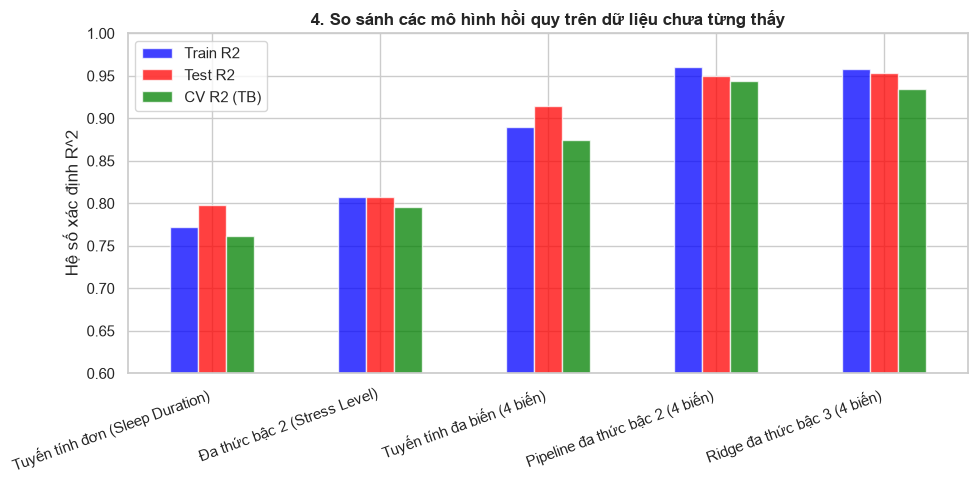

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 4. So sánh bốn mô hình của Chương 6 và mô hình Ridge trên cùng một cách chia theo hồ sơ
FEATURES = ['Sleep Duration', 'Stress Level', 'Heart Rate', 'Physical Activity Level']


def poly_pipe(degree, model):
  return Pipeline([
      ('scale', StandardScaler()),
      ('polynomial', PolynomialFeatures(degree=degree, include_bias=False)),
      ('model', model),
  ])


# Tên mô hình -> (các biến đầu vào, mô hình)
models = {
    'Tuyến tính đơn (Sleep Duration)': (['Sleep Duration'], LinearRegression()),
    'Đa thức bậc 2 (Stress Level)': (['Stress Level'], poly_pipe(2, LinearRegression())),
    'Tuyến tính đa biến (4 biến)': (FEATURES, LinearRegression()),
    'Pipeline đa thức bậc 2 (4 biến)': (FEATURES, poly_pipe(2, LinearRegression())),
    'Ridge đa thức bậc 3 (4 biến)': (FEATURES, poly_pipe(3, Ridge(alpha=best_alpha))),
}

# Một lần chia Train/Test + 5-Fold CV theo hồ sơ
rows = []
for name, (cols, est) in models.items():
  m = clone(est).fit(x_train[cols], y_train)
  cv = cross_val_score(
      clone(est), X_data[cols], Y, cv=GroupKFold(n_splits=5), groups=groups
  )
  rows.append({
      'Mô hình': name,
      'Train R2': m.score(x_train[cols], y_train),
      'Test R2': m.score(x_test[cols], y_test),
      'Test MSE': mean_squared_error(y_test, m.predict(x_test[cols])),
      'CV R2 (TB)': cv.mean(),
      'CV R2 (thấp nhất)': cv.min(),
  })
compare_df = pd.DataFrame(rows).set_index('Mô hình')
print(compare_df.round(4).to_string())

# Độ ổn định: lặp lại 30 cách chia Train/Test khác nhau
stability = {name: [] for name in models}
repeat_split = GroupShuffleSplit(n_splits=30, test_size=0.3, random_state=1)
for tr_idx, te_idx in repeat_split.split(X_data, Y, groups):
  for name, (cols, est) in models.items():
    m = clone(est).fit(X_data.iloc[tr_idx][cols], Y.iloc[tr_idx])
    stability[name].append(m.score(X_data.iloc[te_idx][cols], Y.iloc[te_idx]))
stability_df = pd.DataFrame(stability)
print()
print('Test R2 qua 30 lần chia:')
print(stability_df.agg(['mean', 'min', 'max', 'std']).T.round(4).to_string())

# Vẽ biểu đồ so sánh
ax = compare_df[['Train R2', 'Test R2', 'CV R2 (TB)']].plot(
    kind='bar', figsize=(10, 5), color=['blue', 'red', 'green'], alpha=0.75
)
ax.set_ylim(0.6, 1.0)
ax.set_xlabel('')
ax.set_ylabel('Hệ số xác định R^2')
ax.set_title(
    '4. So sánh các mô hình hồi quy trên dữ liệu chưa từng thấy',
    fontsize=12,
    fontweight='bold',
)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()